In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:
# Load the dataset
df = pd.read_excel("dataset/Online Retail.xlsx")

# Display first 5 rows
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check data types and non-null values
print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

Column Names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
# Count missing values in each column
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
# Calculate percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64


In [6]:
# Remove rows where CustomerID is missing
df = df.dropna(subset=['CustomerID'])

print("Dataset shape after removing missing CustomerID:")
print(df.shape)

Dataset shape after removing missing CustomerID:
(406829, 8)


In [7]:
# Check missing values after cleaning
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [8]:
# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 5225


In [9]:
# Check transactions with negative quantities
print("Negative quantity records:", (df['Quantity'] < 0).sum())

Negative quantity records: 8905


In [10]:
# Check transactions with zero or negative unit prices
print("Zero or negative prices:", (df['UnitPrice'] <= 0).sum())

Zero or negative prices: 40


In [11]:
# Remove duplicate transactions
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (401604, 8)
Remaining duplicates: 0


In [12]:
# Keep only valid purchase transactions
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

print("Dataset shape after removing invalid transactions:", df.shape)

Dataset shape after removing invalid transactions: (392692, 8)


In [13]:
# Verify cleaned dataset
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nMinimum Quantity:", df['Quantity'].min())
print("Minimum Unit Price:", df['UnitPrice'].min())

Dataset Information:
<class 'pandas.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  object        
 1   StockCode    392692 non-null  object        
 2   Description  392692 non-null  object        
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  float64       
 7   Country      392692 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 27.0+ MB

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Duplicate Records: 0

Minimum Quantity: 1
Minimum Unit Price: 0.001


In [14]:
# Convert CustomerID to integer
df['CustomerID'] = df['CustomerID'].astype(int)

# Check the data type
print(df['CustomerID'].dtype)

int64


In [15]:
# Calculate revenue for each transaction
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Display first 5 rows
df[['Quantity', 'UnitPrice', 'Revenue']].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [16]:
df['Revenue'].describe()

count    392692.000000
mean         22.631500
std         311.099224
min           0.001000
25%           4.950000
50%          12.450000
75%          19.800000
max      168469.600000
Name: Revenue, dtype: float64

In [17]:
# Extract month and year from InvoiceDate
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

# Display first 5 rows
df[['InvoiceDate', 'InvoiceMonth']].head()

,InvoiceDate,InvoiceMonth
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


In [18]:
# Calculate total revenue for each month
monthly_sales = df.groupby('InvoiceMonth')['Revenue'].sum()

# Display monthly revenue
print(monthly_sales)

InvoiceMonth
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: Revenue, dtype: float64


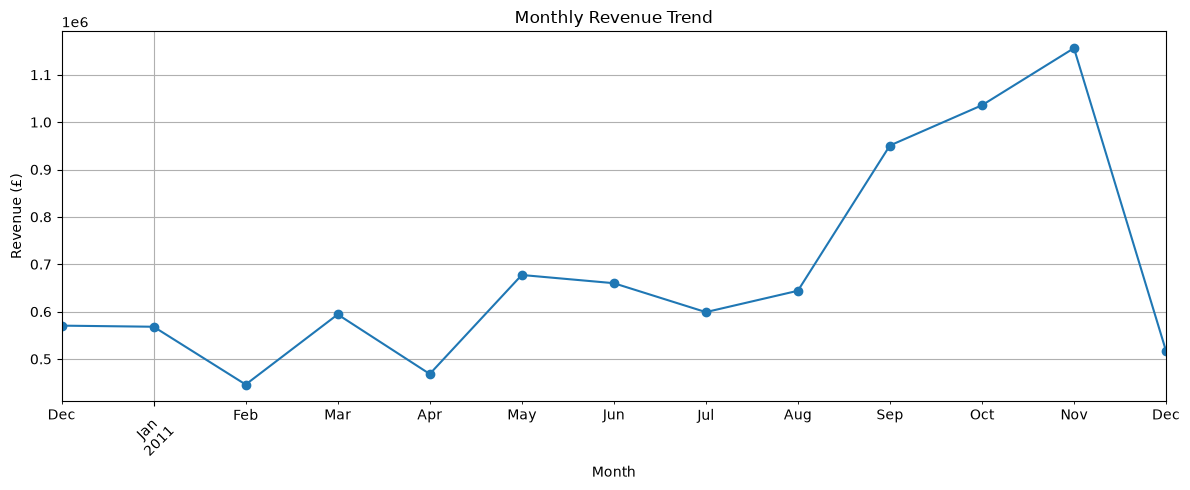

In [19]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
# Calculate total revenue by country
country_sales = df.groupby('Country')['Revenue'].sum()

# Sort countries by revenue
country_sales = country_sales.sort_values(ascending=False)

# Display top 10 countries
print(country_sales.head(10))


Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


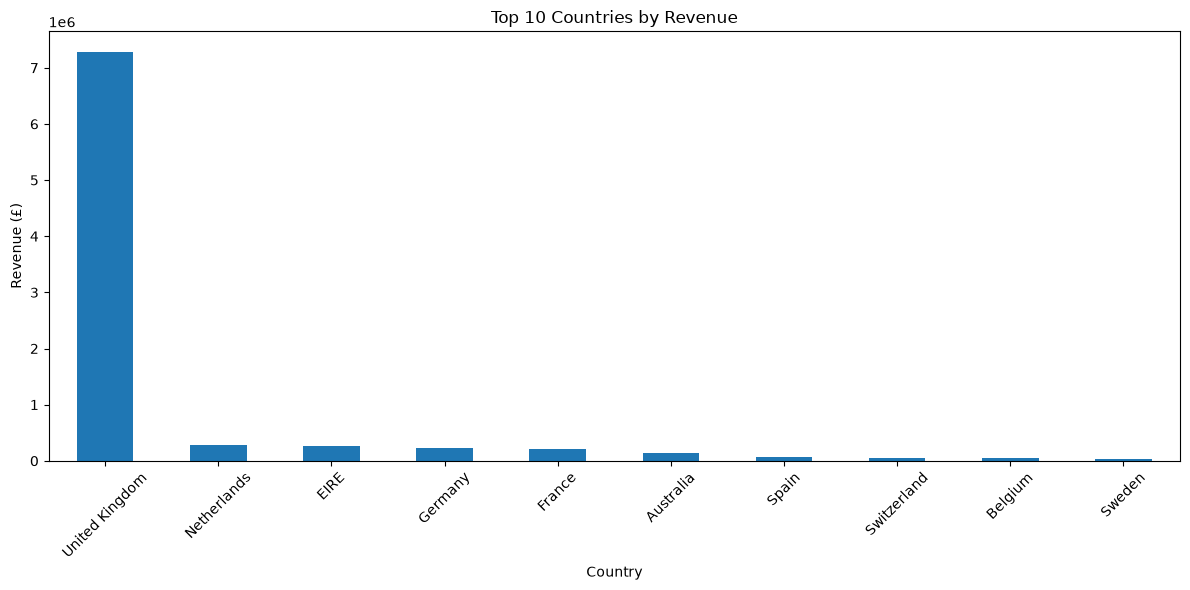

In [21]:
plt.figure(figsize=(12, 6))

country_sales.head(10).plot(kind='bar')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Country')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [22]:
print(country_sales.head(10))

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


In [23]:
# Set reference date as one day after the last transaction
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Reference Date:", snapshot_date)

Reference Date: 2011-12-10 12:50:00


In [24]:
# Calculate RFM metrics for each customer

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'Revenue': 'sum'
})

# Rename columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'Revenue': 'Monetary'
}, inplace=True)

# Display first 5 customers
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [25]:
# Summary statistics of RFM metrics
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [26]:
print("Total customers:", rfm.shape[0])

print("\nAverage Recency:", rfm['Recency'].mean())
print("Average Frequency:", rfm['Frequency'].mean())
print("Average Monetary:", rfm['Monetary'].mean())

Total customers: 4338

Average Recency: 92.53642231443061
Average Frequency: 4.272014753342554
Average Monetary: 2048.688080682342


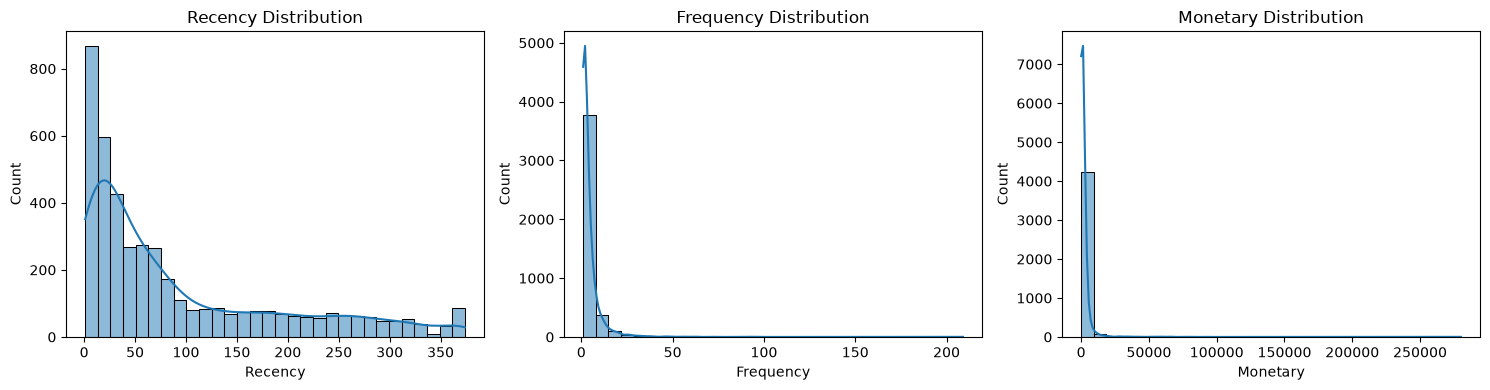

In [27]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], bins=30, kde=True)
plt.title('Recency Distribution')

plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], bins=30, kde=True)
plt.title('Frequency Distribution')

plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], bins=30, kde=True)
plt.title('Monetary Distribution')

plt.tight_layout()
plt.show()

In [28]:
print("RFM Skewness:")

print(rfm.skew())

RFM Skewness:
Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64


In [29]:
# Apply log transformation to RFM values
rfm_log = rfm.copy()

rfm_log['Recency'] = np.log1p(rfm_log['Recency'])
rfm_log['Frequency'] = np.log1p(rfm_log['Frequency'])
rfm_log['Monetary'] = np.log1p(rfm_log['Monetary'])

# Display first 5 rows
rfm_log.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,5.789960,0.693147,11.253955
12347,1.098612,2.079442,8.368925
12348,4.330733,1.609438,7.494564
12349,2.995732,0.693147,7.472245
12350,5.739793,0.693147,5.815324


In [30]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit and transform RFM data
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    index=rfm.index,
    columns=rfm.columns
)

rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


In [31]:
rfm_scaled.describe()

,Recency,Frequency,Monetary
count,4.338000e+03,4.338000e+03,4.338000e+03
mean,-8.025955e-17,-8.189750e-18,-3.669008e-16
std,1.000115e+00,1.000115e+00,1.000115e+00
min,-2.341296e+00,-9.552143e-01,-3.997811e+00
25%,-6.613615e-01,-9.552143e-01,-6.835802e-01
50%,8.992557e-02,-3.615828e-01,-6.510929e-02
75%,8.447915e-01,6.532370e-01,6.572178e-01
max,1.564198e+00,5.858535e+00,4.732381e+00


In [32]:
# Calculate WCSS for different values of K

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

print(wcss)

[13013.999999999998, 6483.589425039294, 4869.488628540215, 3939.04938163916, 3296.7087076425432, 2855.764068043109, 2548.820244849562, 2336.341053610392, 2156.0056725213444, 2005.7462362695574]


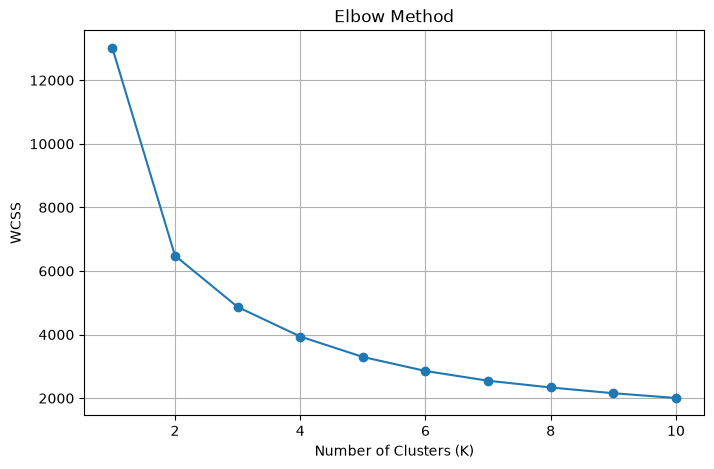

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.grid(True)
plt.show()

In [34]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

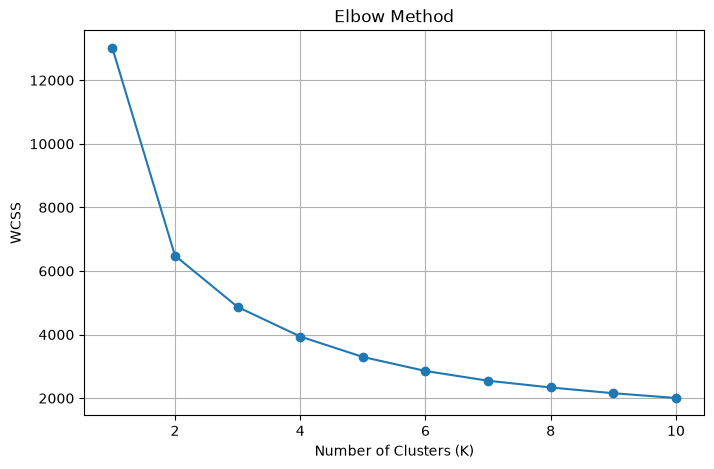

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.grid(True)
plt.show()

In [36]:
# Apply K-Means clustering
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# Assign clusters to customers
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Display first 10 customers
rfm.head(10)


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,3
12347,2,7,4310.00,0
12348,75,4,1797.24,3
12349,19,1,1757.55,2
12350,310,1,334.40,1
12352,36,8,2506.04,3
12353,204,1,89.00,1
12354,232,1,1079.40,1
12355,214,1,459.40,1


In [37]:
# Count customers in each cluster
print(rfm['Cluster'].value_counts().sort_index())

Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [38]:
# Calculate average RFM values for each cluster
cluster_analysis = rfm.groupby('Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean()

print(cluster_analysis)

            Recency  Frequency     Monetary
Cluster                                    
0         12.171108  13.751753  8088.018331
1        181.506782   1.316893   340.998626
2         17.698925   2.192354   557.322616
3         71.635506   4.078902  1801.777893


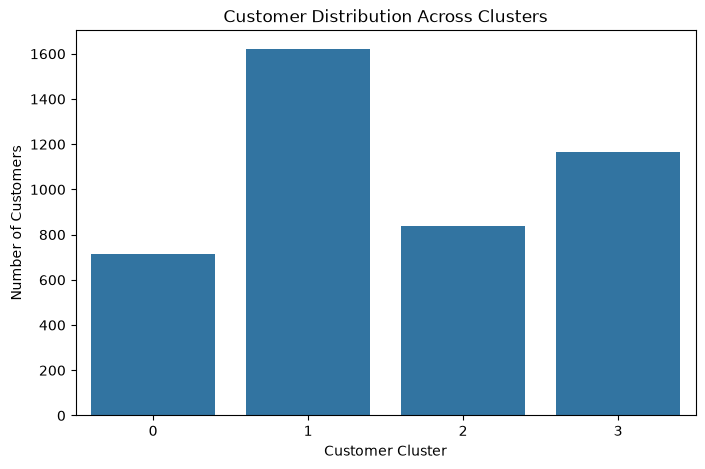

In [39]:
plt.figure(figsize=(8, 5))

sns.countplot(data=rfm, x='Cluster')

plt.title('Customer Distribution Across Clusters')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()


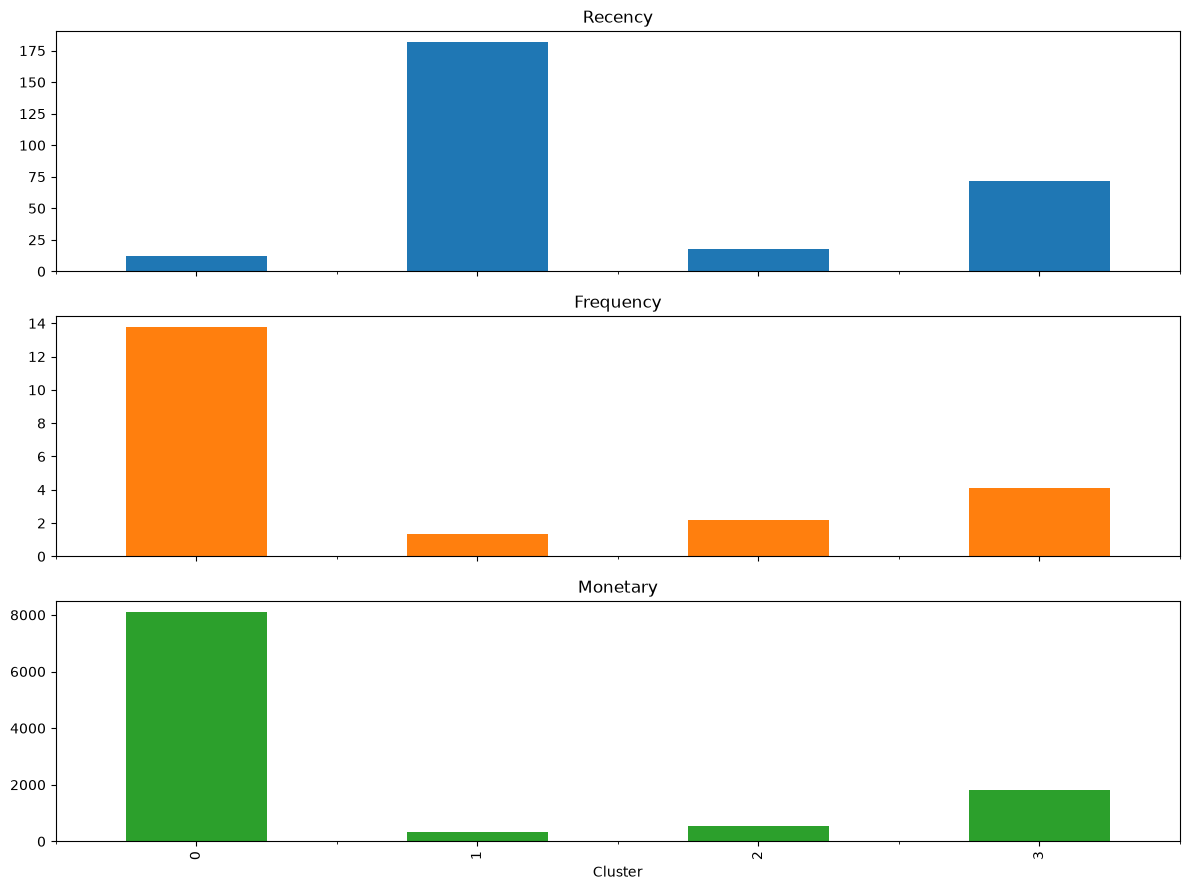

In [40]:
cluster_analysis.plot(
    kind='bar',
    subplots=True,
    figsize=(12, 9),
    layout=(3, 1),
    legend=False
)

plt.tight_layout()
plt.show()

In [41]:
rfm.to_csv('Customer_Segmentation_Results.csv')

print("Customer segmentation results saved successfully!")

Customer segmentation results saved successfully!


In [42]:
# Extract invoice month
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

df[['CustomerID', 'InvoiceDate', 'InvoiceMonth']].head()

,CustomerID,InvoiceDate,InvoiceMonth
0,17850,2010-12-01 08:26:00,2010-12
1,17850,2010-12-01 08:26:00,2010-12
2,17850,2010-12-01 08:26:00,2010-12
3,17850,2010-12-01 08:26:00,2010-12
4,17850,2010-12-01 08:26:00,2010-12


In [43]:
# Find the first purchase month for each customer
df['CohortMonth'] = df.groupby('CustomerID')['InvoiceMonth'].transform('min')

df[['CustomerID', 'InvoiceMonth', 'CohortMonth']].head()

,CustomerID,InvoiceMonth,CohortMonth
0,17850,2010-12,2010-12
1,17850,2010-12,2010-12
2,17850,2010-12,2010-12
3,17850,2010-12,2010-12
4,17850,2010-12,2010-12


In [44]:
# Calculate the number of unique customers in each cohort
cohort_data = df.groupby(
    ['CohortMonth', 'CohortIndex']
)['CustomerID'].nunique()

# Convert into a table
cohort_table = cohort_data.unstack()

# Display cohort table
cohort_table

KeyError: 'CohortIndex'

In [45]:
print(df.columns.tolist())


['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'InvoiceMonth', 'CohortMonth']


In [46]:
# Calculate cohort index
df['CohortIndex'] = (
    (df['InvoiceMonth'].dt.year - df['CohortMonth'].dt.year) * 12
    + (df['InvoiceMonth'].dt.month - df['CohortMonth'].dt.month)
    + 1
)

# Verify the result
df[['CustomerID', 'InvoiceMonth', 'CohortMonth', 'CohortIndex']].head(10)

,CustomerID,InvoiceMonth,CohortMonth,CohortIndex
0,17850,2010-12,2010-12,1
1,17850,2010-12,2010-12,1
2,17850,2010-12,2010-12,1
3,17850,2010-12,2010-12,1
4,17850,2010-12,2010-12,1
5,17850,2010-12,2010-12,1
6,17850,2010-12,2010-12,1
7,17850,2010-12,2010-12,1
8,17850,2010-12,2010-12,1
9,13047,2010-12,2010-12,1


In [47]:
cohort_data = df.groupby(
    ['CohortMonth', 'CohortIndex']
)['CustomerID'].nunique()

cohort_table = cohort_data.unstack()

cohort_table


CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [48]:
# Get the number of customers in the first month
cohort_sizes = cohort_table.iloc[:, 0]

# Calculate customer retention percentage
retention = cohort_table.divide(cohort_sizes, axis=0) * 100

# Display retention table
retention.round(2)

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


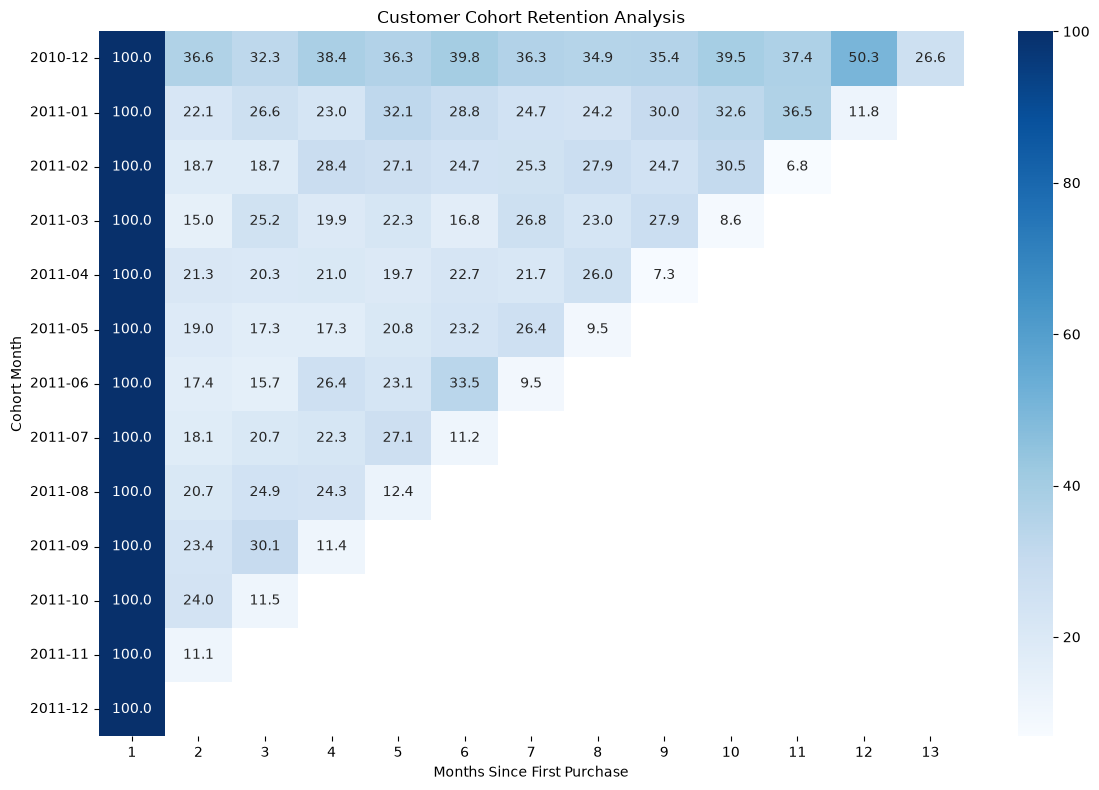

In [49]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    retention,
    annot=True,
    fmt='.1f',
    cmap='Blues'
)

plt.title('Customer Cohort Retention Analysis')
plt.xlabel('Months Since First Purchase')
plt.ylabel('Cohort Month')

plt.tight_layout()
plt.show()